# Cointegrated Pairs Trading
## Trading Games — Palazzi (2025)

**Strategy family: statistical arbitrage / pairs trading.** Two coins that share a stationary
spread can be traded when that spread is unusually wide. The strategy is long the cheap leg
and short the rich leg, then exits when the spread reverts, volatility is too high, or a
trailing stop on the spread is hit.

Here is the trading process, following Palazzi (2025):

1. **Fit the hedge on the backtest only.** For log prices $Y_1$ and $Y_2$,
   $Y_{1,t}=\mu+\gamma Y_{2,t}+\epsilon_t$. The spread is $S_t=Y_{1,t}-\gamma Y_{2,t}$.
   $\mu$ and $\gamma$ are estimated on the backtest window and then held fixed.

2. **Enter on a Z-score extreme.** Over the last $L$ days,
   $Z_t=(S_t-\bar S_{L,t})/\sigma_{L,t}$.
   Go long the spread when $Z\le -0.7$ and short the spread when $Z\ge 0.7$.
   Otherwise stay flat. $L$ is chosen by a grid search from 5 to 360 days.

3. **Filter high volatility.** Compute the 30-day volatility of spread changes.
   If it exceeds 1.5 times the backtest-average volatility, force the position to cash.

4. **Trail a stop on the spread.** After entry, track the best spread extreme.
   A long spread is stopped if the spread falls $2.5\%$ below its peak, scaled up when
   volatility is above its backtest average. A short spread uses the symmetric rule.

5. **Pick one pair, then freeze it.** Among directed pairs that pass Engle–Granger
   cointegration at 5% on the backtest, keep the pair and lookback with the highest
   backtest net Sharpe. That choice is frozen before any validation number is computed.
   The paper's reported LTC–DOGE pair is kept as a separate predeclared anchor.

**Reference:** Palazzi, R. B. (2025), *Trading Games: Beating Passive Strategies in the
Bullish Crypto Market*, Journal of Futures Markets, 45, 1911–1933.
[DOI 10.1002/fut.70018](https://doi.org/10.1002/fut.70018).

**Fixed research dates:** prices run from **2021-01-01 through 2026-09-17**. Strategy returns
use a fixed chronological 70/30 split: **Backtest 2021-01-02 through 2024-12-31** and
**Validation 2025-01-01 through 2026-09-17**. These dates apply to every pair. The paper's
own sample was ten CoinMarketCap coins from 2019 through May 2024; this notebook keeps the
paper's trading rules and applies them to the shared 30-coin research universe and timeline.

Run all cells in order. The single input is `OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv`;
no data download is needed. Dependencies: NumPy, pandas, Matplotlib, statsmodels, and IPython.


**Reporting conventions and alpha uncertainty.** Headline tables, rankings, charts, and unqualified `Sharpe` fields use **252-day Sharpe**, $\sqrt{252}\,\bar r/s_r$, with zero risk-free return. The main performance tables also report **Sharpe (365)** on the identical daily observations. This is a reporting convention: cryptocurrency observations remain calendar-daily, including weekends. CAGR, annual volatility, Sortino, turnover, linear annual alpha, borrowing accrual, and strategy risk sizing retain their documented 365-day calendar convention. Alpha is the intercept of the stated benchmark regression; its **HAC t-statistic and pointwise 95% confidence interval** accompany return results. Daily BTC regressions use 20 HAC lags, a finite-sample covariance correction, and Student-t critical values. Annual alpha and its bounds are daily estimates multiplied by 365 (and by 100 when displayed as percent), not compounded returns. Intervals crossing zero do not establish positive alpha. These intervals do not correct the prior strategy search or make development data unseen. **We do not change strategies to obtain a t-statistic above 2**; doing so would create further selection bias.

**Cost convention:** 20 bps per dollar traded is the baseline all-in transaction cost (approximately 7 bps commission plus 13 bps slippage). Legacy ledger fields named `fee` or `trading_fees` record this combined cost, not commission alone. Extra execution/borrowing cost scenarios are evaluated only as sensitivities in the final portfolio notebook.


## 1. Research design and experiment map

The **research universe always contains the same 30 coins**. Every ordered pair of those coins
is a candidate. No outside coin is introduced.

**Selection rule fixed before evaluation:** on the backtest only, keep directed pairs with an
Engle–Granger p-value below 5%. For each survivor, search every integer lookback from 5 to 360
and retain the lookback with the highest backtest net Sharpe. Then choose the pair with the
highest of those Sharpes. Exact ties use lower annual turnover, then alphabetical pair id.
Freeze that pair and lookback before calculating validation performance.

The paper's published winner, **LTC versus DOGE**, remains a separate predeclared anchor.
Its lookback is still chosen on the backtest only. It does not have to pass cointegration
to be reported, and it is not allowed to replace the frozen selection after validation.

The volatility anchor, hedge ratio, and cointegration screen all use backtest prices only.
Validation prices are used once, after the freeze, to score the frozen rules.


### What the constants are doing

The dates below are the same 70/30 cut used in the Donchian notebook. Backtest ends on
**2024-12-31**. Validation starts the next day and is not allowed to choose the pair,
the hedge, or the lookback.

The numbers next to the strategy are Palazzi's published rules, written out so a later
cell does not have to hide them inside a function.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from IPython.display import display, Markdown
from statsmodels.tsa.stattools import coint
from statsmodels.tools.sm_exceptions import CollinearityWarning

NOTEBOOK_NAME = "Pairs_trading Palazzi_et_al.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
# Shared input prices are stored beside this notebook.
DATA_DIR = Path("OHLCV_Market_Cap_Data")
OUTPUT_ROOT = Path("output") / "palazzi_pairs"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
# Standard 70-30 Backtest Validation Split

LOOKBACKS = list(range(5, 361))
# LOOKBACKS: every integer window from 5 through 360 days. The grid picks one of these on the backtest only.
ENTRY_Z = 0.7
# ENTRY_Z = 0.7: long the spread when Z is at or below -0.7, short it when Z is at or above +0.7.
VOL_LOOKBACK = 30
# VOL_LOOKBACK = 30: volatility of daily spread changes is measured on the latest 30 days.
VOL_MULT = 1.5
# VOL_MULT = 1.5: if today's spread volatility is above 1.5 times the backtest average, the signal is forced to cash.
STOP_BASE = 0.025
# Start with a 2.5% trailing stop and widen it when volatility rises.
COINT_ALPHA = 0.05
# Only pairs passing the 5% cointegration test can be selected.
MIN_COINT_OBS = 365
# Require a year of shared price history before estimating the hedge.

COST_BPS = 20
# Apply 20 bps per unit change in the spread position.
COST_RATE = COST_BPS / 10_000
# COST_BPS = 20: one-way cost on a change in the spread position. Same 20 bps convention as the Donchian notebook.
PERIODS_PER_YEAR, HAC_LAGS = 365, 20
# Annualize over 365 days; use 20 HAC lags for the BTC regression.
PAPER_ANCHOR = ("LTC-USD", "DOGE-USD")
# Keep the paper's LTC DOGE pair as a reference, whatever our backtest selects.

SHARPE_PERIODS_PER_YEAR = 252


def alpha_uncertainty(fit, periods=365):
    """Pointwise HAC alpha inference; annual bounds are linear percentages."""
    bounds = np.asarray(fit.conf_int(alpha=0.05))[0]
    return {"Alpha HAC t": float(np.asarray(fit.tvalues)[0]),
            "Alpha 95% CI low (%)": float(bounds[0] * periods * 100),
            "Alpha 95% CI high (%)": float(bounds[1] * periods * 100)}


def btc_alpha_metrics(r, benchmark):
    import statsmodels.api as sm
    aligned = pd.concat({"strategy": r, "BTC": benchmark.reindex(r.index)}, axis=1).dropna()
    if len(aligned) != len(r):
        raise ValueError("BTC alpha requires a benchmark observation for every account return date")
    fit = sm.OLS(aligned.strategy.to_numpy(), sm.add_constant(aligned.BTC.to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(20, len(aligned)-1), "use_correction": True}, use_t=True)
    return {"Alpha vs BTC (%)": float(fit.params[0] * 36500),
            "Beta vs BTC": float(fit.params[1]), "Alpha HAC p": float(fit.pvalues[0]),
            **alpha_uncertainty(fit)}


### Chart helpers

These two helpers only control how a figure is labeled and stored. They do not touch prices,
signals, or the account. `FIGURES` keeps each plot so the export cell can write the same
image that was shown in the notebook.

Consistent colors and chart formatting across pair comparisons.


In [2]:
COLORS = {"anchor": "#176b87", "selected": "#d08a35", "btc": "#94a3b8"}
# Keep the paper's pair, our selected pair, and BTC easy to distinguish.
pd.set_option("display.float_format", "{:.4f}".format)
# Round the displayed tables to four decimals.

# Use the same plot style throughout the notebook.
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}

def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight() * 72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15)
    fig.text(0.06, 0.99 - 23 / height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99 - 43 / height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)


## Universe

The research universe is the same fixed 30-coin list used by the Donchian study. A pair can
only be formed from coins inside this list. `UNI7083-USD` is Yahoo's old label; the file
itself stores that coin as `UNI-USD`.


In [3]:
# Same 30 coins as our other studies, grouped for a quick overview.
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"]
}

tickers = [t for members in SECTORS.values() for t in members]
# Bring all the groups into one ticker list.
ASSETS = sorted("UNI-USD" if t == "UNI7083-USD" else t for t in tickers)
# Use the usual UNI label and keep the coin order consistent.
assert len(ASSETS) == len(set(ASSETS)) == 30
# Quick check: 30 coins, with no duplicates.
display(pd.DataFrame([{"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
                      for sector, members in SECTORS.items()]))


,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


## Load the daily file

Time to input everything from the csv. Prices and volume are already downloaded. This cell
checks that the file is the full 30-coin calendar, then cuts it to the study dates. Nothing
is filled in. A missing or nonpositive close stops the notebook instead of becoming a made-up price.

Daily simple returns start on **2021-01-02**, so the first price day is only a starting level.
`PERIOD_DATES` is the object every later cell uses when it says "backtest" or "validation".


In [4]:
# Time to input everything from the csv files.
# Coin prices are already downloaded into OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv
INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Missing bundled input: {INPUT_PATH.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files."
    )

# Hash and parse the same bytes; the run manifest records the exact CSV used.
input_bytes = INPUT_PATH.read_bytes()
input_hashes = {INPUT_PATH.name: hashlib.sha256(input_bytes).hexdigest()}
market_data = pd.read_csv(BytesIO(input_bytes))
required_columns = {"date", "symbol", "open", "high", "low", "close", "volume"}
if not required_columns.issubset(market_data.columns):
    raise ValueError(f"Missing input columns: {sorted(required_columns - set(market_data.columns))}")
market_data["date"] = pd.to_datetime(market_data["date"], format="%Y-%m-%d", errors="raise")
if market_data["date"].isna().any() or market_data["symbol"].isna().any():
    raise ValueError("Missing dates or symbols in the input CSV.")
if market_data.duplicated(["date", "symbol"]).any():
    raise ValueError("Duplicate date/symbol observations in the input CSV.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols:
    raise ValueError("Input CSV must contain exactly the fixed 30-coin universe.")
for field in ["close", "volume"]:
    market_data[field] = pd.to_numeric(market_data[field], errors="raise")

# Preserve the strategy's established asset labels, including UNI-USD.
market_data["asset"] = market_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
volume = market_data.pivot(index="date", columns="asset", values="volume").sort_index()
# Explicit sample dates below exclude unavailable observations beyond this study.
for label, frame in [("prices", prices), ("volume", volume)]:
    if set(frame.columns) != set(ASSETS):
        raise ValueError(f"{label}: input must contain exactly the fixed 30 assets.")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{label}: dates must be sorted and unique.")
prices = prices.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
volume = volume.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
if not prices.index.equals(volume.index):
    raise ValueError("Price and volume dates differ.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
if not prices.index.equals(expected_calendar):
    raise ValueError("Snapshot must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require a data review; no price imputation.")


# Calculate daily returns; the first close has no previous price to compare with.
returns = prices.pct_change(fill_method=None).iloc[1:]
# Use the fixed backtest and validation dates from the settings.
PERIOD_DATES = {
    "Backtest": returns.loc[BACKTEST_START:BACKTEST_END].index,
    "Validation": returns.loc[VALIDATION_START:VALIDATION_END].index,
}

# Make sure the two periods cover the full return history in order.
assert PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(returns.index)
print(f"Loaded {len(ASSETS)} coins and {len(prices):,} daily prices from {SAMPLE_START} through {SAMPLE_END}.")
print(f"Data file: {INPUT_PATH.relative_to(NOTEBOOK_DIR).as_posix()}")
display(prices.head())


Loaded 30 coins and 2,086 daily prices from 2021-01-01 through 2026-09-17.
Data file: OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv


asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,90.3497,0.1753,0.3981,5.8686,3.6648,341.9856,37.9050,29374.1519,0.6223,0.0057,...,1.3573,1.2940,0.0370,1.8421,1.9715,0.0269,4.7362,0.0191,0.1324,0.2374
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,32127.2679,0.6142,0.0106,...,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,32782.0245,0.6723,0.0098,...,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,31971.9135,0.6770,0.0098,...,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,33992.4293,0.6870,0.0099,...,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268


## 2. Spread, Z-score, volatility filter, and stop

For a directed pair $(Y, X)$, the backtest log prices determine
$\hat\mu$ and $\hat\gamma$. The traded spread on every later day is
$S_t=\log P_{Y,t}-\hat\gamma\log P_{X,t}$.

The lookback $L$ defines a causal rolling mean and standard deviation of $S$.
A long-spread position is $+1$ and a short-spread position is $-1$. The published
return, after a position change, is

$$R_t=\mathrm{Signal}_{t-1}\,\Delta S_t-c\,|\Delta\mathrm{Signal}_t|$$

with $c=0.002$ (20 bps). This is a cost on the change in the spread position, matching
the paper's transaction-cost term at the same 20 bps rate used in the other notebooks.
Cash earns zero. There is no borrow or funding charge.

The 30-day volatility filter and the 2.5% trailing stop both use a volatility anchor
equal to the mean 30-day spread-change volatility **inside the backtest**. That anchor
is not recomputed on the validation sample. The paper averages volatility over its full
published sample; doing that here would let 2025–2026 prices affect the filter, so this
notebook keeps the anchor inside the backtest.


### Equation-to-code map

| Object in the paper | Name in the code |
|---|---|
| Dependent log price $Y_1$ | `log_y` |
| Hedge log price $Y_2$ | `log_x` |
| Intercept $\mu$ and hedge $\gamma$ | `mu`, `gamma` |
| Spread $S_t=Y_1-\gamma Y_2$ | `spread` |
| Rolling Z-score | `z` |
| Position $+1$, $-1$, or $0$ | `signal` |
| Backtest-only average volatility | `vol_anchor` |
| 20 bps on a position change | `cost_rate` |

The hedge and the volatility anchor are fit on prices through **2024-12-31**. Later days can
update the rolling Z-score, because that window only looks backward, but they cannot refit $\gamma$.


In [5]:
def fit_hedge(log_y, log_x):

    # Fit log(Y) against log(X), allowing for a constant offset.
    design = np.column_stack([np.ones(len(log_x)), log_x])
    coef, _, rank, _ = np.linalg.lstsq(design, log_y, rcond=None)

    # Skip the pair if we can't estimate both coefficients reliably.
    if rank != 2:
        return None
    # mu is the offset; gamma is the hedge coefficient.
    mu, gamma = float(coef[0]), float(coef[1])
    if not np.isfinite(mu) or not np.isfinite(gamma):
        return None
    return mu, gamma

def cointegration_pvalue(log_y, log_x):
    # Engle-Granger p-value. Failed or nearly collinear tests are recorded as missing.
    # Other warnings remain visible; numerical failures cannot select a pair.
    with warnings.catch_warnings():
        warnings.simplefilter("error", CollinearityWarning)
        try:
            _, pvalue, _ = coint(log_y, log_x, trend="c", autolag="aic")
        except Exception:
            return np.nan
    return float(pvalue) if np.isfinite(pvalue) else np.nan


### Signal state versus the trailing stop

The Z-score says which side of the spread we want. The stop is a separate variable. It watches
the best spread level since entry and can force the position back to cash even when Z is still
outside the band. A volatility spike does the same thing through `filtered`.

Check the return lines at the bottom of the next cell. Gross return is yesterday's position
times today's spread change. The 20 bps cost is charged only when that position changes.
The first `lookback` days are warmup: the Z-score does not exist yet, so those days are left
as missing rather than scored as a flat zero.


In [6]:
def simulate_spread(log_y, log_x, gamma, lookback, vol_anchor, cost_rate=COST_RATE):
    """Paper signal, stop, and return on one aligned pair. Index is the caller's index."""

    # Build the log spread using the fixed hedge coefficient.
    spread = log_y - gamma * log_x
    series = pd.Series(spread)
    # Use the spread's recent history to define its usual level and variation.
    roll_mean = series.rolling(lookback, min_periods=lookback).mean()
    roll_std = series.rolling(lookback, min_periods=lookback).std(ddof=0)
    # Z_t: distance of today's spread from its own trailing mean, in trailing standard deviations.
    # How far is today's spread from its rolling average?
    z = ((series - roll_mean) / roll_std.replace(0, np.nan)).to_numpy()
    change = np.empty(len(spread))
    change[0] = np.nan
    change[1:] = np.diff(spread)
    vol = pd.Series(change).rolling(VOL_LOOKBACK, min_periods=VOL_LOOKBACK).std(ddof=0).to_numpy()

    # Track daily spread changes, then estimate their recent volatility.
    raw = np.zeros(len(spread))
    # Go long when the spread is low, short when it's high, and flat in between.
    raw[np.isfinite(z) & (z <= -ENTRY_Z)] = 1.0
    raw[np.isfinite(z) & (z >= ENTRY_Z)] = -1.0
    filtered = raw.copy()

    # Sit out high-volatility days using the fixed backtest threshold.
    filtered[np.isfinite(vol) & (vol > VOL_MULT * vol_anchor)] = 0.0

    signal = np.zeros(len(spread))
    position = 0.0
    extreme = np.nan
    stops = 0
    for t in range(len(spread)):
        desired = filtered[t]
        # Check the stop on the existing position before accepting today's signal.

        if position != 0.0 and np.isfinite(spread[t]):
            scale = max(vol[t] / vol_anchor, 1.0) if np.isfinite(vol[t]) and vol_anchor > 0 else 1.0
            width = STOP_BASE * scale
            # Track the highest spread for a long and the lowest for a short.
            if position > 0:
                extreme = spread[t] if not np.isfinite(extreme) else max(extreme, spread[t])
                if spread[t] < extreme * (1.0 - width):
                    desired = 0.0
                    stops += 1
            else:
                extreme = spread[t] if not np.isfinite(extreme) else min(extreme, spread[t])
                if spread[t] > extreme * (1.0 + width):
                    desired = 0.0
                    stops += 1
        # Reset the tracked extreme whenever the position changes.
        if desired != position:
            extreme = np.nan if desired == 0.0 else spread[t]
            position = desired
        signal[t] = position

    net = np.full(len(spread), np.nan)
    gross = np.full(len(spread), np.nan)
    turnover = np.full(len(spread), np.nan)

    # A direct switch from long to short counts as two units of turnover.
    delta_signal = np.diff(signal, prepend=0.0)

    # Skip the initial warm-up when recording returns and costs.
    turnover[lookback:] = np.abs(delta_signal[lookback:])
    # Yesterday's position earns today's spread change.
    gross[lookback:] = signal[lookback - 1:-1] * change[lookback:]
    # Deduct the cost of today's position change.
    net[lookback:] = gross[lookback:] - cost_rate * turnover[lookback:]
    return net, gross, turnover, int(stops), signal


### Fitting one pair without looking at 2025–2026

`prepare_pair` is the only place $\gamma$ and the volatility anchor are estimated. Both use
`train`, which stops at the backtest end date. The cointegration flag is the gate for the
search. A pair that fails it is still written to the screen, but `best_lookback` is never called on it.


In [7]:
def prepare_pair(asset_y, asset_x):
    """Fit γ and the volatility anchor on the backtest window only."""
    # Keep the dates where both coins have prices.
    frame = prices[[asset_y, asset_x]].dropna()
    # Estimate the pair using only prices through the backtest end.
    train = frame.loc[:BACKTEST_END]

    # Skip pairs without enough shared history.
    if len(train) < MIN_COINT_OBS:
        return None
    log_train = np.log(train.to_numpy(dtype=float))
    # Fit the hedge using the two log-price series.
    fitted = fit_hedge(log_train[:, 0], log_train[:, 1])
    if fitted is None:
        return None
    mu, gamma = fitted
    # Check cointegration on that same backtest sample.
    pvalue = cointegration_pvalue(log_train[:, 0], log_train[:, 1])
    log_all = np.log(frame.to_numpy(dtype=float))

    # Carry the backtest hedge into validation without refitting it.
    spread = log_all[:, 0] - gamma * log_all[:, 1]
    change = np.diff(spread, prepend=np.nan)
    vol = pd.Series(change, index=frame.index).rolling(VOL_LOOKBACK, min_periods=VOL_LOOKBACK).std(ddof=0)
    # Freeze average backtest volatility as the reference level.
    anchor = float(vol.loc[:BACKTEST_END].mean())

    # Skip the pair if its volatility baseline is unusable.
    if not np.isfinite(anchor) or anchor <= 0:
        return None

    # Keep the estimates and price history together for the lookback search.
    return {
        "asset_y": asset_y, "asset_x": asset_x,
        "pair_id": f"{asset_y.replace('-USD','')}/{asset_x.replace('-USD','')}",
        "mu": mu, "gamma": gamma, "pvalue": pvalue,
        "cointegrated": bool(np.isfinite(pvalue) and pvalue < COINT_ALPHA),
        "vol_anchor": anchor,
        "index": frame.index,
        "log_y": log_all[:, 0], "log_x": log_all[:, 1],
    }


## 3. Backtest selection and validation

All standardized performance tables use daily net returns after the 20 bps position-change
cost. Total Return and CAGR describe compounded performance. Volatility, Sharpe, and Sortino
use 365-day annualization, and drawdown includes starting wealth of one. Positive Days is the
share of daily net returns above zero. Skewness and Pearson kurtosis describe the daily
return distribution.

Alpha, beta, the HAC p-value, and the Information Ratio use the same daily BTC benchmark.
HAC standard errors retain 20 lags. These statistics are descriptive and are not adjusted
for the number of pairs and lookbacks searched. Selecting the best backtest pair creates
selection bias, so validation stability matters more than the winning in-sample rank.

The search scores every integer lookback, but only after the hedge and cointegration test
have been fit on the backtest. Validation returns are not computed until the winning pair
and its lookback have been written down.


### How a lookback gets chosen

`performance` is the same daily scorecard as the Donchian notebook: compounded CAGR, a 365-day
Sharpe with a zero cash rate, and a HAC regression on BTC. It describes a path. It does not
search.

`best_lookback` does the search, and only on the dates it is given. The call site below passes
the backtest index. A higher Sharpe wins. A tie goes to the lower average turnover, then the
shorter lookback.


In [8]:

def wealth_and_drawdown(r):
    # Compound returns and measure drawdown from the running peak, including starting capital.
    wealth = (1 + r).cumprod()
    return wealth, wealth / wealth.cummax().clip(lower=1) - 1

def performance(r, benchmark):
    # Leave out unscored dates, then align the benchmark.
    r = r.dropna()
    benchmark = benchmark.reindex(r.index)
    aligned = pd.concat({"strategy": r, "benchmark": benchmark}, axis=1, sort=True).dropna()
    wealth, dd = wealth_and_drawdown(r)
    sd = r.std(ddof=1)
    # For Sortino, measure downside relative to a zero return.
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))
    cagr = wealth.iloc[-1] ** (365 / len(r)) - 1
    # Estimate alpha and beta against BTC, allowing for serial dependence in the errors.
    fit = sm.OLS(aligned["strategy"].to_numpy(), sm.add_constant(aligned["benchmark"].to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(HAC_LAGS, len(aligned) - 1), "use_correction": True}, use_t=True)

    # Measure the variation left after accounting for BTC exposure.
    residual_sd = np.std(fit.resid, ddof=1)
    return {"N dates": len(r), "Total return (%)": 100 * (wealth.iloc[-1] - 1), "CAGR (%)": 100 * cagr,
            "Volatility (%)": 100 * sd * np.sqrt(365), "Sharpe": np.sqrt(SHARPE_PERIODS_PER_YEAR) * r.mean() / sd if sd > 0 else np.nan, "Sharpe (365)": np.sqrt(365) * r.mean() / sd if sd > 0 else np.nan,
            "Sortino": np.sqrt(365) * r.mean() / downside if downside > 0 else np.nan,
            "Max drawdown (%)": 100 * dd.min(), "Positive days (%)": 100 * (r > 0).mean(),
            "Alpha vs BTC (%)": 36500 * fit.params[0], "Beta vs BTC": fit.params[1],
            "Alpha HAC p": fit.pvalues[0], **alpha_uncertainty(fit),
            "Information ratio": fit.params[0] * np.sqrt(365) / residual_sd if residual_sd > 1e-12 else np.nan,
            "Skewness": r.skew(), "Pearson kurtosis": r.kurt() + 3}


# Keep the main performance measures together for the tables.
CORE_METRICS = ["Total return (%)", "CAGR (%)", "Volatility (%)", "Sharpe", "Sharpe (365)", "Sortino",
                "Max drawdown (%)", "Positive days (%)", "Annual turnover", "Alpha vs BTC (%)", "Alpha HAC t", "Alpha 95% CI low (%)", "Alpha 95% CI high (%)"]
# Then add BTC-relative results and return-distribution statistics.
INSTITUTIONAL_METRICS = ["Alpha vs BTC (%)", "Beta vs BTC", "Alpha HAC p",
                         "Information ratio", "Skewness", "Pearson kurtosis"]

def score_window(net, gross, turnover, dates, benchmark):
    # Put returns and turnover on the requested evaluation dates.
    frame = pd.DataFrame({"net": net, "gross": gross, "turnover": turnover}, index=dates).reindex(benchmark.index)
    rows = {}
    # Report performance before and after trading costs.
    for basis in ["gross", "net"]:
        rows[basis] = {**performance(frame[basis], benchmark),
                       "Annual turnover": 365 * frame["turnover"].mean()}
    return frame, rows

def best_lookback(pair, score_index):
    """Choose L on one date index. The scorer must not include validation dates."""
    best = None
    # Try every window using the supplied backtest scoring dates.
    for lookback in LOOKBACKS:
        net, gross, turnover, stops, _ = simulate_spread(
            pair["log_y"], pair["log_x"], pair["gamma"], lookback, pair["vol_anchor"])
        series = pd.Series(net, index=pair["index"]).reindex(score_index).dropna()
        # Skip windows with too few scored observations.
        if len(series) < lookback:
            continue
        sd = series.std(ddof=1)
        sharpe = np.sqrt(SHARPE_PERIODS_PER_YEAR) * series.mean() / sd if sd > 0 else np.nan
        turnover_mean = float(pd.Series(turnover, index=pair["index"]).reindex(score_index).mean())
        # Skip candidates without a usable Sharpe ratio.
        if not np.isfinite(sharpe):
            continue
        candidate = {"lookback": lookback, "sharpe": float(sharpe), "turnover": turnover_mean, "stops": stops}
        # Highest net Sharpe wins; ties favor less turnover, then a shorter window.
        if best is None or (candidate["sharpe"], -candidate["turnover"], -candidate["lookback"]) > (
                best["sharpe"], -best["turnover"], -best["lookback"]):
            best = candidate
    return best


### Freeze the winner before validation exists as a score

Every ordered pair is tested. Only a backtest Engle–Granger pass is allowed into the lookback
grid. The first row of the leaderboard is the frozen strategy. Printing it here is the line
in the sand: the next cells may score 2025–2026, but they may not pick a different pair.


In [9]:
# Screen every directed pair on the backtest, then freeze one winner.
backtest_dates = PERIOD_DATES["Backtest"]
candidates = []
screens = []
n_directed = len(ASSETS) * (len(ASSETS) - 1)
print(f"Screening {n_directed} directed pairs on the backtest only...")
for i, asset_y in enumerate(ASSETS):
    for asset_x in ASSETS:
        if asset_y == asset_x:
            continue
        pair = prepare_pair(asset_y, asset_x)
        if pair is None:
            continue
        screens.append({
            "pair_id": pair["pair_id"], "asset_y": asset_y, "asset_x": asset_x,
            "pvalue": pair["pvalue"], "gamma": pair["gamma"], "cointegrated": pair["cointegrated"],
        })
        # A failed cointegration test is audited and then skipped. It cannot win on Sharpe.
        if not pair["cointegrated"]:
            continue
        chosen = best_lookback(pair, backtest_dates)
        if chosen is None:
            continue
        candidates.append({**{k: pair[k] for k in ["pair_id", "asset_y", "asset_x", "mu", "gamma", "pvalue", "vol_anchor"]},
                           **chosen})
    if (i + 1) % 5 == 0:
        print(f"  {i + 1}/{len(ASSETS)} dependent coins screened; cointegrated candidates so far: {len(candidates)}")

screen_table = pd.DataFrame(screens).sort_values(["cointegrated", "pvalue"], ascending=[False, True])
leaderboard = pd.DataFrame(candidates).sort_values(
    ["sharpe", "turnover", "pair_id"], ascending=[False, True, True], kind="stable"
).reset_index(drop=True)
if leaderboard.empty:
    raise RuntimeError("No cointegrated pair produced a finite backtest Sharpe.")

selected = leaderboard.iloc[0].to_dict()
frozen_selection = {
    "selected_pair": selected["pair_id"],
    "asset_y": selected["asset_y"],
    "asset_x": selected["asset_x"],
    "lookback": int(selected["lookback"]),
    "backtest_sharpe": float(selected["sharpe"]),
    "gamma": float(selected["gamma"]),
    "coint_pvalue": float(selected["pvalue"]),
    "selection_criterion": "Backtest net Sharpe among EG p<0.05 pairs; ties use lower turnover, then pair id",
    "candidate_count": int(len(leaderboard)),
    "directed_pairs": int(n_directed),
    "cointegrated_pairs": int(screen_table["cointegrated"].sum()),
    "backtest_last_date": str(backtest_dates[-1].date()),
    "cost_bps": COST_BPS,
}
print("Backtest selection frozen:", frozen_selection["selected_pair"],
      "L* =", frozen_selection["lookback"],
      "backtest Sharpe =", round(frozen_selection["backtest_sharpe"], 3))
print(f"Cointegrated on the backtest: {frozen_selection['cointegrated_pairs']} / {n_directed}")
display(leaderboard.head(15)[["pair_id", "lookback", "sharpe", "turnover", "pvalue", "gamma"]])


Screening 870 directed pairs on the backtest only...


  5/30 dependent coins screened; cointegrated candidates so far: 16


  10/30 dependent coins screened; cointegrated candidates so far: 74


  15/30 dependent coins screened; cointegrated candidates so far: 107


  20/30 dependent coins screened; cointegrated candidates so far: 118


  25/30 dependent coins screened; cointegrated candidates so far: 140


  30/30 dependent coins screened; cointegrated candidates so far: 155
Backtest selection frozen: THETA/VET L* = 136 backtest Sharpe = 1.339
Cointegrated on the backtest: 155 / 870


,pair_id,lookback,sharpe,turnover,pvalue,gamma
0,THETA/VET,136,1.3388,0.1555,0.0030,1.1668
1,ETC/VET,291,1.2663,0.0949,0.0036,0.5140
2,FIL/VET,227,1.1771,0.1629,0.0048,1.5644
3,ETC/HBAR,343,1.1738,0.0993,0.0011,0.4487
4,ETC/THETA,309,1.1580,0.1181,0.0023,0.3630
5,UNI/VET,100,1.0252,0.1506,0.0140,0.8317
6,ADA/HBAR,304,1.0013,0.1901,0.0043,0.8782
7,ETC/ADA,315,0.9838,0.0986,0.0050,0.5448
8,ETC/UNI,246,0.9675,0.1646,0.0076,0.4575
9,AAVE/XLM,217,0.9018,0.1150,0.0019,1.0014


## 4. Frozen evaluation

The selected pair is replayed with its frozen hedge, lookback, and volatility anchor.
Backtest and validation are separate wealth paths: each starts at 1 and is liquidated at
its own endpoint. History before each window is used only to warm the rolling Z-score.
The paper anchor, LTC versus DOGE, is scored the same way in both orientations. Its
lookback is the backtest optimum for that orientation. Validation does not change either choice.


The function below does not search. It replays one hedge and one lookback, then cuts the
path into the two date blocks. Each block is its own wealth path starting at 1.

LTC/DOGE is tried in both directions. The direction with the better **backtest** Sharpe
becomes the paper anchor. Validation is a column in the table, not an input to that choice.


In [10]:
def evaluate_frozen(asset_y, asset_x, lookback):
    pair = prepare_pair(asset_y, asset_x)
    if pair is None:
        raise RuntimeError(f"Cannot prepare {asset_y} / {asset_x}")
    net, gross, turnover, stops, signal = simulate_spread(
        pair["log_y"], pair["log_x"], pair["gamma"], int(lookback), pair["vol_anchor"])
    path = pd.DataFrame({
        "net": net, "gross": gross, "turnover": turnover, "signal": signal,
    }, index=pair["index"])
    pieces = {}
    metrics_rows = []
    for period, dates in PERIOD_DATES.items():
        benchmark = returns.loc[dates, "BTC-USD"]
        frame, rows = score_window(path["net"], path["gross"], path["turnover"], path.index, benchmark)
        pieces[period] = frame
        for basis, values in rows.items():
            metrics_rows.append({"Period": period, "Strategy": pair["pair_id"], "Basis": basis, "Lookback": int(lookback), **values})
    return pair, path, pieces, pd.DataFrame(metrics_rows), stops

# Validation is scored only after `selected` has already been frozen.
selected_pair, selected_path, selected_pieces, selected_metrics, selected_stops = evaluate_frozen(
    selected["asset_y"], selected["asset_x"], selected["lookback"])

anchor_rows = []
anchor_bundle = {}
# Both orientations of the paper pair. The backtest Sharpe, not the validation Sharpe, picks one.
for asset_y, asset_x in [PAPER_ANCHOR, PAPER_ANCHOR[::-1]]:
    pair = prepare_pair(asset_y, asset_x)
    if pair is None:
        continue
    chosen = best_lookback(pair, PERIOD_DATES["Backtest"])
    if chosen is None:
        continue
    bundle = evaluate_frozen(asset_y, asset_x, chosen["lookback"])
    anchor_rows.append({
        "pair_id": pair["pair_id"], "lookback": chosen["lookback"],
        "backtest_sharpe": chosen["sharpe"], "cointegrated": pair["cointegrated"], "pvalue": pair["pvalue"],
    })
    anchor_bundle[pair["pair_id"]] = bundle

anchor_choice = pd.DataFrame(anchor_rows).sort_values("backtest_sharpe", ascending=False).iloc[0]
anchor_id = anchor_choice["pair_id"]
anchor_pair, anchor_path, anchor_pieces, anchor_metrics, anchor_stops = anchor_bundle[anchor_id]
frozen_selection["paper_anchor"] = anchor_id
frozen_selection["paper_anchor_lookback"] = int(anchor_choice["lookback"])
frozen_selection["paper_anchor_cointegrated"] = bool(anchor_choice["cointegrated"])

metrics = pd.concat([selected_metrics, anchor_metrics], ignore_index=True)
metrics = metrics.drop_duplicates(["Period", "Strategy", "Basis"], keep="first")
print("Paper anchor frozen on the backtest:", anchor_id, "L* =", int(anchor_choice["lookback"]),
      "cointegrated =", bool(anchor_choice["cointegrated"]))
display(metrics.set_index(["Period", "Strategy", "Basis"])[CORE_METRICS].round(3))


Paper anchor frozen on the backtest: LTC/DOGE L* = 29 cointegrated = False


Total return (%)  CAGR (%)  Volatility (%)  \
Period     Strategy  Basis                                               
Backtest   THETA/VET gross         1429.4990  111.9870         46.3680   
                     net            917.0910   89.4520         46.1410   
Validation THETA/VET gross            1.0580    0.6170         40.0960   
                     net            -16.8710  -10.2290         39.9620   
Backtest   LTC/DOGE  gross          867.7440   78.3440         49.6450   
                     net            389.2470   49.8830         49.2450   
Validation LTC/DOGE  gross          -23.9710  -14.7900         46.0700   
                     net            -40.3880  -26.0740         45.6570   

                            Sharpe  Sharpe (365)  Sortino  Max drawdown (%)  \
Period     Strategy  Basis                                                    
Backtest   THETA/VET gross  1.5360        1.8480   3.1430          -31.5700   
                     net    1.3390        1.6110   2.7050          -32.1370   
Validation THETA/VET gross  0.1800        0.2170   0.2980          -36.5830   
                     net   -0.0570       -0.0690  -0.0930          -39.4680   
Backtest   LTC/DOGE  gross  1.1760        1.4160   2.0820          -41.6800   
                     net    0.8890        1.0700   1.5500          -43.5270   
Validation LTC/DOGE  gross -0.0990       -0.1190  -0.1700          -39.9320   
                     net   -0.3610       -0.4340  -0.6120          -49.7450   

                            Positive days (%)  Annual turnover  \
Period     Strategy  Basis                                       
Backtest   THETA/VET gross            28.9060          56.7470   
                     net              28.8300          56.7470   
Validation THETA/VET gross            33.6000          57.2320   
                     net              33.6000          57.2320   
Backtest   LTC/DOGE  gross            31.4250          87.9360   
                     net              31.3550          87.9360   
Validation LTC/DOGE  gross            35.6800          71.8320   
                     net              35.6800          71.8320   

                            Alpha vs BTC (%)  Alpha HAC t  \
Period     Strategy  Basis                                  
Backtest   THETA/VET gross           87.5590       4.1090   
                     net             76.1970       3.6500   
Validation THETA/VET gross            8.5750       0.3230   
                     net             -2.8720      -0.1090   
Backtest   LTC/DOGE  gross           66.4450       3.2030   
                     net             48.8810       2.4150   
Validation LTC/DOGE  gross           -5.0990      -0.1880   
                     net            -19.4610      -0.7280   

                            Alpha 95% CI low (%)  Alpha 95% CI high (%)  
Period     Strategy  Basis                                               
Backtest   THETA/VET gross               45.7510               129.3660  
                     net                 35.2430               117.1520  
Validation THETA/VET gross              -43.5860                60.7350  
                     net                -54.7570                49.0130  
Backtest   LTC/DOGE  gross               25.7570               107.1330  
                     net                  9.1840                88.5780  
Validation LTC/DOGE  gross              -58.3920                48.1940  
                     net                -71.9700                33.0490

## 5. Backtest-to-validation comparison

`Selected in backtest` is true only for the pair chosen from backtest data and then carried
unchanged into validation. The paper anchor is reported beside it. Red borders on the chart
mark a validation Sharpe below half of a positive backtest Sharpe.


### How to read the bars

Blue and coral are the backtest. Green and red are validation. A red outline means the
validation Sharpe fell below half of a positive backtest Sharpe. That outline is a warning
about persistence. It is not a new ranking, and it does not change `frozen_selection`.

The equity chart starts a fresh \$1 account in each period. A dashed line is validation.
BTC buy-and-hold is the passive line on the same dates.


,Role,Lookback,Backtest Sharpe,Backtest CAGR (%),Backtest Max DD (%),Validation Sharpe,Validation CAGR (%),Validation Max DD (%)
Pair,,,,,,,,
THETA/VET,Selected in backtest,136,1.3390,89.4520,-32.1370,-0.0570,-10.2290,-39.4680
LTC/DOGE,Paper anchor,29,0.8890,49.8830,-43.5270,-0.3610,-26.0740,-49.7450


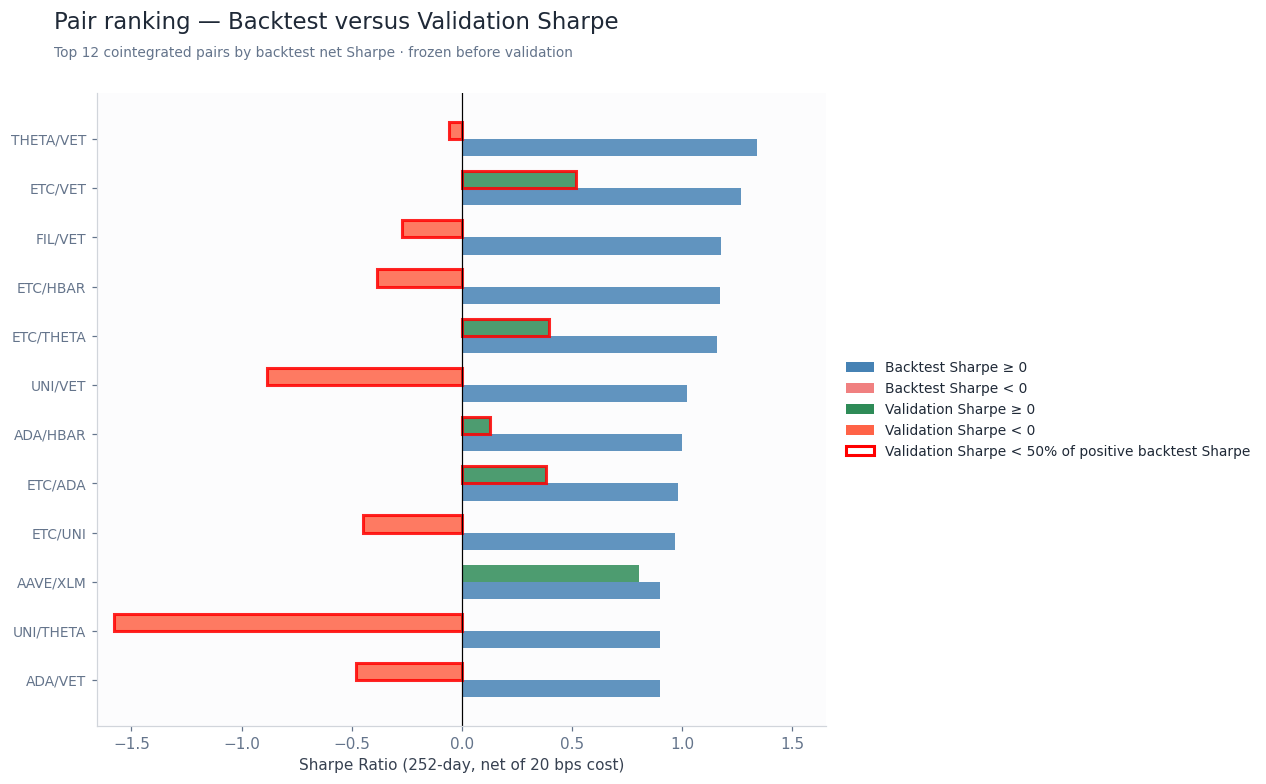

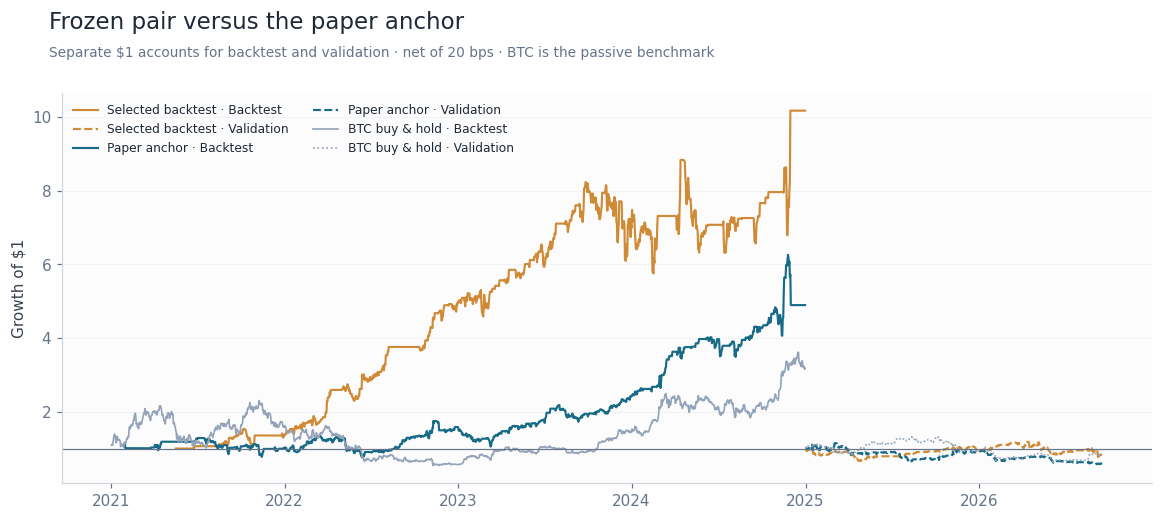

,Backtest Sharpe,Validation Sharpe
pair_id,,
THETA/VET,1.3390,-0.0570
ETC/VET,1.2660,0.5200
FIL/VET,1.1770,-0.2730
ETC/HBAR,1.1740,-0.3840
ETC/THETA,1.1580,0.3950
UNI/VET,1.0250,-0.8840
ADA/HBAR,1.0010,0.1290
ETC/ADA,0.9840,0.3820
ETC/UNI,0.9680,-0.4470


In [11]:
comparison_rows = []
for label, key, pieces, spec in [
    ("Selected in backtest", selected["pair_id"], selected_pieces, selected),
    ("Paper anchor", anchor_id, anchor_pieces, anchor_choice),
]:
    row = {"Role": label, "Pair": key, "Lookback": int(spec["lookback"])}
    for period, frame in pieces.items():
        row[f"{period} Sharpe"] = performance(frame["net"], returns.loc[frame.index, "BTC-USD"])["Sharpe"]
        row[f"{period} CAGR (%)"] = performance(frame["net"], returns.loc[frame.index, "BTC-USD"])["CAGR (%)"]
        row[f"{period} Max DD (%)"] = performance(frame["net"], returns.loc[frame.index, "BTC-USD"])["Max drawdown (%)"]
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows).set_index("Pair")
display(comparison.round(3))

# Top backtest pairs, with validation scored only after the freeze above.
top = leaderboard.head(12).copy()
validation_sharpes = []
for _, row in top.iterrows():
    _, _, pieces, _, _ = evaluate_frozen(row["asset_y"], row["asset_x"], row["lookback"])
    validation_sharpes.append(performance(pieces["Validation"]["net"], returns.loc[pieces["Validation"].index, "BTC-USD"])["Sharpe"])
top["Validation Sharpe"] = validation_sharpes
top = top.rename(columns={"sharpe": "Backtest Sharpe"})
chart = top.set_index("pair_id")[["Backtest Sharpe", "Validation Sharpe"]]

# Horizontal comparison uses the same ordering and rows as the table above.
y = np.arange(len(chart))
bar_height = 0.35
fig, ax = plt.subplots(figsize=(12, max(6, 0.48 * len(chart) + 1.5)))
backtest_colors = ["steelblue" if value >= 0 else "lightcoral" for value in chart["Backtest Sharpe"]]
validation_colors = ["seagreen" if value >= 0 else "tomato" for value in chart["Validation Sharpe"]]
ax.barh(y + bar_height / 2, chart["Backtest Sharpe"].to_numpy(), bar_height,
        color=backtest_colors, alpha=0.85)
validation_bars = ax.barh(y - bar_height / 2, chart["Validation Sharpe"].to_numpy(), bar_height,
                          color=validation_colors, alpha=0.85)
# Red borders flag a validation Sharpe below half of a positive backtest Sharpe.
for bar, backtest_value, validation_value in zip(
        validation_bars, chart["Backtest Sharpe"], chart["Validation Sharpe"]):
    if backtest_value > 0 and validation_value < 0.5 * backtest_value:
        bar.set_edgecolor("red")
        bar.set_linewidth(2.0)
ax.set_yticks(y)
ax.set_yticklabels(chart.index, fontsize=9)
ax.invert_yaxis()
# Use equal positive and negative ranges so the zero line is visually centered.
sharpe_limit = 1.05 * np.nanmax(np.abs(chart[["Backtest Sharpe", "Validation Sharpe"]].to_numpy()))
ax.set_xlim(-sharpe_limit, sharpe_limit)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Sharpe Ratio (252-day, net of 20 bps cost)")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="steelblue", label="Backtest Sharpe ≥ 0"),
    Patch(facecolor="lightcoral", label="Backtest Sharpe < 0"),
    Patch(facecolor="seagreen", label="Validation Sharpe ≥ 0"),
    Patch(facecolor="tomato", label="Validation Sharpe < 0"),
    Patch(facecolor="none", edgecolor="red", linewidth=2, label="Validation Sharpe < 50% of positive backtest Sharpe"),
], loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
show_figure(fig, "strategy_train_validation_sharpe",
            "Pair ranking — Backtest versus Validation Sharpe",
            "Top 12 cointegrated pairs by backtest net Sharpe · frozen before validation")

fig, ax = plt.subplots(figsize=(11, 4.8))
for label, pieces, color in [
    ("Selected backtest", selected_pieces, COLORS["selected"]),
    ("Paper anchor", anchor_pieces, COLORS["anchor"]),
]:
    for period, linestyle in [("Backtest", "-"), ("Validation", "--")]:
        wealth, _ = wealth_and_drawdown(pieces[period]["net"].dropna())
        ax.plot(wealth.index, wealth.to_numpy(), color=color, linestyle=linestyle, linewidth=1.4,
                label=f"{label} · {period}")
btc_panels = []
for period, dates in PERIOD_DATES.items():
    wealth, _ = wealth_and_drawdown(returns.loc[dates, "BTC-USD"])
    ax.plot(wealth.index, wealth.to_numpy(), color=COLORS["btc"], linestyle=":" if period == "Validation" else "-",
            linewidth=1.1, label=f"BTC buy & hold · {period}")
ax.axhline(1, color="#64748b", linewidth=0.8)
ax.set_ylabel("Growth of $1")
polish_axis(ax, date_axis=True)
ax.legend(ncol=2, fontsize=8)
show_figure(fig, "selected_versus_anchor_equity",
            "Frozen pair versus the paper anchor",
            "Separate $1 accounts for backtest and validation · net of 20 bps · BTC is the passive benchmark")
display(chart.round(3))


## 6. Reproducible research outputs

Export the cointegration screen, backtest leaderboard, frozen choice, daily gross and net
returns, and the figure files. Input checksums, date boundaries, the 20 bps cost, and
software versions identify the run. Research outputs go to `output/palazzi_pairs/` beside
the notebook. Existing files with the same names are overwritten on each run.


In [12]:
OUTPUT_DIR = OUTPUT_ROOT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
screen_table.to_csv(OUTPUT_DIR / "cointegration_screen.csv", index=False)
leaderboard.to_csv(OUTPUT_DIR / "backtest_leaderboard.csv", index=False)
metrics.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
comparison.reset_index().to_csv(OUTPUT_DIR / "backtest_validation_comparison.csv", index=False)
chart.reset_index().to_csv(OUTPUT_DIR / "top12_backtest_validation_sharpe.csv")
for name, path in {
    "selected_daily": selected_path,
    "anchor_daily": anchor_path,
}.items():
    path.to_csv(OUTPUT_DIR / f"{name}.csv")
# The frozen pair is written as it was chosen. This file is the record that validation did not vote.
(OUTPUT_DIR / "frozen_selection.json").write_text(json.dumps(frozen_selection, indent=2))
manifest = {
    "specification": {
        "study": "palazzi_cointegrated_pairs",
        "assets": ASSETS,
        "sample_start": SAMPLE_START,
        "sample_end": SAMPLE_END,
        "backtest_start": BACKTEST_START,
        "backtest_end": BACKTEST_END,
        "validation_start": VALIDATION_START,
        "validation_end": VALIDATION_END,
        "lookbacks": [LOOKBACKS[0], LOOKBACKS[-1]],
        "entry_z": ENTRY_Z,
        "vol_lookback": VOL_LOOKBACK,
        "vol_mult": VOL_MULT,
        "stop_base": STOP_BASE,
        "coint_alpha": COINT_ALPHA,
        "cost_bps": COST_BPS,
        "vol_anchor": "mean 30-day spread volatility inside the backtest only",
        "hedge": "OLS on backtest log prices; held fixed",
        "input_sha256": input_hashes,
    },
    "selection": frozen_selection,
    "environment": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "statsmodels": sm.__version__,
    },
    "figures": list(FIGURES),
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
for name, fig in FIGURES.items():
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
print(f"Saved the frozen selection and {len(FIGURES)} figures to {OUTPUT_DIR.relative_to(NOTEBOOK_DIR).as_posix()}/")


Saved the frozen selection and 2 figures to output/palazzi_pairs/


## 7. Core findings and interpretation

The next cell prints the frozen backtest choice and the validation result from this run.
Those numbers are computed above. They are not copied from the paper's Table 3, and they
are not a reason to change the frozen pair.


In [13]:
# Pull the already-computed rows. This cell does not resimulate and does not reselect.
selected_backtest = metrics.query("Strategy == @selected['pair_id'] and Period == 'Backtest' and Basis == 'net'").iloc[0]
selected_validation = metrics.query("Strategy == @selected['pair_id'] and Period == 'Validation' and Basis == 'net'").iloc[0]
anchor_backtest = metrics.query("Strategy == @anchor_id and Period == 'Backtest' and Basis == 'net'").iloc[0]
anchor_validation = metrics.query("Strategy == @anchor_id and Period == 'Validation' and Basis == 'net'").iloc[0]
findings = f"""
### Does the paper's preferred pair remain ours?

The backtest covers {BACKTEST_START} through {BACKTEST_END}. The validation period covers {VALIDATION_START} through {VALIDATION_END}.
The backtest selected **{selected['pair_id']}** with lookback **{int(selected['lookback'])}** from {frozen_selection['cointegrated_pairs']} cointegrated directed pairs, using net Sharpe at {COST_BPS} bps.
The paper anchor **{anchor_id}** uses lookback **{int(anchor_choice['lookback'])}**. It was cointegrated on this backtest: **{bool(anchor_choice['cointegrated'])}**.

### Backtest results

The selected pair produced a {selected_backtest['CAGR (%)']:.2f}% net CAGR, {selected_backtest['Sharpe']:.3f} net Sharpe (252), and {selected_backtest['Max drawdown (%)']:.2f}% maximum drawdown. Its 365-day Sharpe is {selected_backtest['Sharpe (365)']:.3f}; BTC alpha HAC t = {selected_backtest['Alpha HAC t']:.2f}, with a 95% linear annual alpha interval of [{selected_backtest['Alpha 95% CI low (%)']:.2f}%, {selected_backtest['Alpha 95% CI high (%)']:.2f}%].
The paper anchor produced a {anchor_backtest['CAGR (%)']:.2f}% net CAGR, {anchor_backtest['Sharpe']:.3f} net Sharpe (252), and {anchor_backtest['Max drawdown (%)']:.2f}% maximum drawdown. Its 365-day Sharpe is {anchor_backtest['Sharpe (365)']:.3f}; BTC alpha HAC t = {anchor_backtest['Alpha HAC t']:.2f}, with a 95% linear annual alpha interval of [{anchor_backtest['Alpha 95% CI low (%)']:.2f}%, {anchor_backtest['Alpha 95% CI high (%)']:.2f}%].

### Validation results

The selected pair returned {selected_validation['CAGR (%)']:.2f}% net CAGR with a {selected_validation['Sharpe']:.3f} net Sharpe (252) and {selected_validation['Max drawdown (%)']:.2f}% maximum drawdown. Its 365-day Sharpe is {selected_validation['Sharpe (365)']:.3f}; BTC alpha HAC t = {selected_validation['Alpha HAC t']:.2f}, with a 95% linear annual alpha interval of [{selected_validation['Alpha 95% CI low (%)']:.2f}%, {selected_validation['Alpha 95% CI high (%)']:.2f}%].
The paper anchor returned {anchor_validation['CAGR (%)']:.2f}% net CAGR with a {anchor_validation['Sharpe']:.3f} net Sharpe (252) and {anchor_validation['Max drawdown (%)']:.2f}% maximum drawdown. Its 365-day Sharpe is {anchor_validation['Sharpe (365)']:.3f}; BTC alpha HAC t = {anchor_validation['Alpha HAC t']:.2f}, with a 95% linear annual alpha interval of [{anchor_validation['Alpha 95% CI low (%)']:.2f}%, {anchor_validation['Alpha 95% CI high (%)']:.2f}%].

### Interpretation

This experiment uses the shared 30-coin daily file, a sealed 70/30 split, and a 20 bps cost on position changes.
The hedge, cointegration test, lookback, and volatility anchor are fixed on the backtest.
A higher backtest Sharpe is a selection result. It is not, by itself, evidence that the same pair will remain the best pair after 2024.
"""
display(Markdown(findings))



### Does the paper's preferred pair remain ours?

The backtest covers 2021-01-02 through 2024-12-31. The validation period covers 2025-01-01 through 2026-09-17.
The backtest selected **THETA/VET** with lookback **136** from 155 cointegrated directed pairs, using net Sharpe at 20 bps.
The paper anchor **LTC/DOGE** uses lookback **29**. It was cointegrated on this backtest: **False**.

### Backtest results

The selected pair produced a 89.45% net CAGR, 1.339 net Sharpe (252), and -32.14% maximum drawdown. Its 365-day Sharpe is 1.611; BTC alpha HAC t = 3.65, with a 95% linear annual alpha interval of [35.24%, 117.15%].
The paper anchor produced a 49.88% net CAGR, 0.889 net Sharpe (252), and -43.53% maximum drawdown. Its 365-day Sharpe is 1.070; BTC alpha HAC t = 2.42, with a 95% linear annual alpha interval of [9.18%, 88.58%].

### Validation results

The selected pair returned -10.23% net CAGR with a -0.057 net Sharpe (252) and -39.47% maximum drawdown. Its 365-day Sharpe is -0.069; BTC alpha HAC t = -0.11, with a 95% linear annual alpha interval of [-54.76%, 49.01%].
The paper anchor returned -26.07% net CAGR with a -0.361 net Sharpe (252) and -49.75% maximum drawdown. Its 365-day Sharpe is -0.434; BTC alpha HAC t = -0.73, with a 95% linear annual alpha interval of [-71.97%, 33.05%].

### Interpretation

This experiment uses the shared 30-coin daily file, a sealed 70/30 split, and a 20 bps cost on position changes.
The hedge, cointegration test, lookback, and volatility anchor are fixed on the backtest.
A higher backtest Sharpe is a selection result. It is not, by itself, evidence that the same pair will remain the best pair after 2024.
